# 2. Modelovanje i treniranje


In [3]:
import os, sys, time, warnings, joblib, itertools
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, log_loss

from nn import train_mlp

sns.set_theme(style="whitegrid")
train = pd.read_csv("../data/train.csv"); val = pd.read_csv("../data/val.csv")
classes = pd.read_csv("../data/classes.csv")
ytr, yva = train["label"].values, val["label"].values
print(len(train), len(val))

def report(name, model, Xv, y=yva):
    p = model.predict(Xv)
    print(f"{name:35s} acc={accuracy_score(y, p):.4f}  macro F1={f1_score(y, p, average='macro'):.4f}")

33204 4151


## 2.1 Pretvaranje teksta u brojeve

Neuronska mreža radi sa brojevima, pa svaki naslov pretvaram u vektor. Koristim **TF-IDF** nad dve vrste jedinica:

* **reči** 
* **n-grami karaktera** 

TF-IDF umesto običnog brojanja: reči koje se pojavljuju svuda (`za`, `novo`) dobijaju malu težinu, a retke i specifične veliku. `sublinear_tf=True` stavlja logaritam na broj ponavljanja jer ponavljanje reči u naslovu (`Iphone 11 IPHONE 11 iphone`) ne znači da je 3 puta važnija. Svaki vektor se normalizuje na dužinu 1, pa kratki i dugi naslovi imaju uporediv uticaj. Rečnik i IDF težine se uče samo na trening skupu.


### Test (ablacija) feature parametara
Za poređenje koristim malu mrežu (8 neurona), da bi eksperimenti bili.


In [4]:
def build_features(cfg, fit_df=train, others=(val,)):
    w = TfidfVectorizer(ngram_range=cfg["word_ngrams"], min_df=cfg["min_df"], max_features=cfg.get("max_word"), sublinear_tf=True)
    c = TfidfVectorizer(analyzer="char_wb", ngram_range=cfg["char_ngrams"], min_df=cfg["min_df"], max_features=cfg.get("max_char"), sublinear_tf=True)
    Xs = [sp.hstack([w.fit_transform(fit_df["text"]), c.fit_transform(fit_df["text"])]).tocsr()]
    for d in others:
        Xs.append(sp.hstack([w.transform(d["text"]), c.transform(d["text"])]).tocsr())
    return w, c, Xs

In [ ]:
BASE = dict(word_ngrams=(1, 2), char_ngrams=(2, 5), min_df=1)
candidates = {
    "najbogatije: reči 1-2, karakteri 2-5, min_df=1": BASE,
    "bez bigrama reči": {**BASE, "word_ngrams": (1, 1)},
    "karakteri 3-5 (bez 2-grama)": {**BASE, "char_ngrams": (3, 5)},
    "karakteri 2-4 (bez 5-grama)": {**BASE, "char_ngrams": (2, 4)},
    "karakteri 3-4": {**BASE, "char_ngrams": (3, 4)},
    "reči 1 + karakteri 3-4": {**BASE, "word_ngrams": (1, 1), "char_ngrams": (3, 4)},
    "reči 1 + karakteri 3-4, min_df=2": {**BASE, "word_ngrams": (1, 1), "char_ngrams": (3, 4), "min_df": 2},
    "kao najbogatije, ali max 8k reči + 22k karaktera": {**BASE, "max_word": 8000, "max_char": 22000, "min_df": 3},
}
abl_rows = []
for name, cfg in candidates.items():
    t = time.time()
    _, _, (A, B) = build_features(cfg)
    accs, losses = [], []
    for s in range(2):
        m, h = train_mlp(A, ytr, B, yva, hidden=(8,), alpha=1e-5, seed=s, max_epochs=20, patience=2)
        accs.append(h["val_acc"][h["best_epoch"] - 1]); losses.append(h["val_loss"][h["best_epoch"] - 1])
    abl_rows.append(dict(konfiguracija=name, ulaza=A.shape[1], val_acc=np.mean(accs), val_loss=np.mean(losses), sekundi=time.time() - t))
    print(abl_rows[-1], flush=True) 
abl_df = pd.DataFrame(abl_rows).round(4); abl_df

{'konfiguracija': 'najbogatije: reči 1-2, karakteri 2-5, min_df=1', 'ulaza': 186654, 'val_acc': np.float64(0.9919296555046977), 'val_loss': np.float64(0.026805093097342317), 'sekundi': 286.993093252182}


{'konfiguracija': 'bez bigrama reči', 'ulaza': 123408, 'val_acc': np.float64(0.9916887496988678), 'val_loss': np.float64(0.026387228805019442), 'sekundi': 197.70214939117432}


{'konfiguracija': 'karakteri 3-5 (bez 2-grama)', 'ulaza': 185386, 'val_acc': np.float64(0.9934955432425921), 'val_loss': np.float64(0.026986663727386992), 'sekundi': 284.8172416687012}


{'konfiguracija': 'karakteri 2-4 (bez 5-grama)', 'ulaza': 134080, 'val_acc': np.float64(0.9907251264755481), 'val_loss': np.float64(0.028653761442798298), 'sekundi': 213.88829445838928}


{'konfiguracija': 'karakteri 3-4', 'ulaza': 132812, 'val_acc': np.float64(0.991206938087208), 'val_loss': np.float64(0.028856213205322057), 'sekundi': 207.36222219467163}


{'konfiguracija': 'reči 1 + karakteri 3-4', 'ulaza': 69566, 'val_acc': np.float64(0.9915682967959528), 'val_loss': np.float64(0.028756887251739437), 'sekundi': 115.9038598537445}


{'konfiguracija': 'reči 1 + karakteri 3-4, min_df=2', 'ulaza': 41851, 'val_acc': np.float64(0.9907251264755481), 'val_loss': np.float64(0.03172230401915368), 'sekundi': 71.07803583145142}


{'konfiguracija': 'kao najbogatije, ali max 8k reči + 22k karaktera', 'ulaza': 30000, 'val_acc': np.float64(0.9889183329318236), 'val_loss': np.float64(0.03126024148788276), 'sekundi': 54.16659688949585}


,konfiguracija,ulaza,val_acc,val_loss,sekundi
0,"najbogatije: reči 1-2, karakteri 2-5, min_df=1",186654,0.9919,0.0268,286.9931
1,bez bigrama reči,123408,0.9917,0.0264,197.7021
2,karakteri 3-5 (bez 2-grama),185386,0.9935,0.0270,284.8172
3,karakteri 2-4 (bez 5-grama),134080,0.9907,0.0287,213.8883
4,karakteri 3-4,132812,0.9912,0.0289,207.3622
5,reči 1 + karakteri 3-4,69566,0.9916,0.0288,115.9039
6,"reči 1 + karakteri 3-4, min_df=2",41851,0.9907,0.0317,71.0780
7,"kao najbogatije, ali max 8k reči + 22k karaktera",30000,0.9889,0.0313,54.1666



Izabrana konfiguracija: **reči + 3-4 grami karaktera, bez ograničenja rečnika, 69566 ulaza**. Ona ima praktično istu tačnost kao najbogatija (0.9916 naspram 0.9919)

### Izabrani feature-i

Na osnovu ablacije koristim reči (unigrame) i n-grame karaktera dužine 3 do 4, bez ograničenja rečnika (`min_df=1`).

In [5]:
FEATURES = dict(word_ngrams=(1, 1), char_ngrams=(3, 4), min_df=1)
word_vec, char_vec, (Xtr, Xva) = build_features(FEATURES)
print("dimenzija ulaza:", Xtr.shape)
print("primer reči u rečniku   :", list(word_vec.vocabulary_)[:8])
print("primer n-grama karaktera:", list(char_vec.vocabulary_)[:8])

dimenzija ulaza: (33204, 69566)
primer reči u rečniku   : ['plac', 'na', 'drini', 'reka', 'drina', 'baric', 'baricka', 'gradjevinski']
primer n-grama karaktera: [' pl', 'pla', 'lac', 'ac ', ' pla', 'plac', 'lac ', ' na']


## 2.2 Neuronska mreža: arhitektura

```
ulaz: TF-IDF vektor
   -> Dense(H) + ReLU          skriveni sloj, uči kombinacije feature-a
   -> Dense(10) + softmax       verovatnoća za svaku od 10 grupa
```

* **Softmax**: za višeklasnu klasifikaciju, mreža daje raspodelu verovatnoće po klasama, a gubitak kažnjava model srazmerno tome koliko je malo verovatnoće dao tačnoj klasi.
* **Adam** optimizator, stopa učenja 1e-3, mini-batch 128. Adam sam prilagođava korak po težini, što pomaže jer su feature-i vrlo retki (većina težina se ažurira retko).



In [5]:
t = time.time()
mlp32, h32 = train_mlp(Xtr, ytr, Xva, yva, hidden=(32,), verbose=True)
print(f"najbolja epoha: {h32['best_epoch']}, {time.time()-t:.0f}s")

epoha  1 | train loss 0.1509 acc 0.9946 | val loss 0.1674 acc 0.9892 | 11s


epoha  2 | train loss 0.0431 acc 0.9981 | val loss 0.0676 acc 0.9908 | 11s


epoha  3 | train loss 0.0199 acc 0.9992 | val loss 0.0468 acc 0.9916 | 11s


epoha  4 | train loss 0.0112 acc 0.9995 | val loss 0.0386 acc 0.9925 | 11s


epoha  5 | train loss 0.0072 acc 0.9998 | val loss 0.0345 acc 0.9925 | 10s


...

epoha 15 | train loss 0.0007 acc 1.0000 | val loss 0.0270 acc 0.9921 | 10s


epoha 16 | train loss 0.0006 acc 1.0000 | val loss 0.0270 acc 0.9918 | 10s


epoha 17 | train loss 0.0005 acc 1.0000 | val loss 0.0270 acc 0.9918 | 11s


epoha 18 | train loss 0.0005 acc 1.0000 | val loss 0.0270 acc 0.9918 | 11s


epoha 19 | train loss 0.0004 acc 1.0000 | val loss 0.0271 acc 0.9916 | 11s
najbolja epoha: 17, 203s


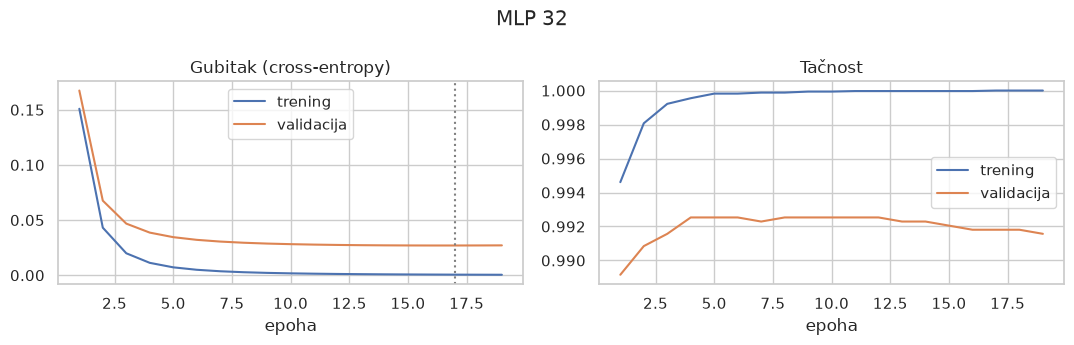

In [6]:
def plot_hist(h, title):
    ep = np.arange(1, len(h["val_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(ep, h["train_loss"], label="trening"); ax[0].plot(ep, h["val_loss"], label="validacija")
    ax[0].axvline(h["best_epoch"], ls=":", c="gray"); ax[0].set_title("Gubitak (cross-entropy)"); ax[0].legend()
    ax[1].plot(ep, h["train_acc"], label="trening"); ax[1].plot(ep, h["val_acc"], label="validacija")
    ax[1].set_title("Tačnost"); ax[1].legend()
    for a in ax: a.set_xlabel("epoha")
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_hist(h32, "MLP 32")

Analiza:

* Gubitak na treningu pada skoro do nule (0.0004), tačnost na treningu je već posle ~10 epoha 100%.
* Gubitak na validaciji pada do epohe ~15 (0.0270), zatim je ravan; tačnost na validaciji stoji oko 99.2%.
* Razlika treninga i validacije znači da mreža jeste potpuno naučila trening skup.
* Rano zaustavljanje je izabralo epohu 17, kad se validacioni gubitak više ne poboljšava.

## 2.3 Koliko neurona? Premala i prevelika mreža

Broj neurona u skrivenom sloju određuje kapacitet mreže:

* **premala** mreža ne može da nauči razliku između klasa (underfitting): i trening i validacija loši,
* **prevelika** mreža može da zapamti trening skup (overfitting): trening skoro savršen, validacija lošija ili gubitak na validaciji raste.

Zato probam više veličina i poredim trening i validaciju. Dodajem i jednu mrežu sa dva skrivena sloja (32-16) samo kao prvu orijentaciju; više slojeva sistematski ispitujem u odeljku 2.5.

In [ ]:
configs = {"2": (2,), "4": (4,), "8": (8,), "32": (32,), "128": (128,), "32-16": (32, 16)}
sweep, hists = [], {}
for name, hl in configs.items():
    t = time.time()
    if name == "32":
        m, h = mlp32, h32
    else:
        m, h = train_mlp(Xtr, ytr, Xva, yva, hidden=hl)
    b = h["best_epoch"] - 1
    sweep.append(dict(sloj=name, epoha=h["best_epoch"], train_acc=h["train_acc"][b],
                      val_acc=h["val_acc"][b], train_loss=h["train_loss"][b], val_loss=h["val_loss"][b],
                      sekundi=time.time() - t))
    hists[name] = h
    print(sweep[-1])
sweep = pd.DataFrame(sweep).round(4); sweep

{'sloj': '2', 'parametara': 139152, 'epoha': 25, 'train_acc': 0.9499457896638959, 'val_acc': 0.9103830402312696, 'train_loss': 0.25127473197645384, 'val_loss': 0.34086360338935345, 'sekundi': 18.015228271484375}


{'sloj': '4', 'parametara': 278304, 'epoha': 25, 'train_acc': 0.9998494157330442, 'val_acc': 0.9857865574560347, 'train_loss': 0.006284993995854308, 'val_loss': 0.057470814542055305, 'sekundi': 36.72800874710083}


{'sloj': '8', 'parametara': 556608, 'epoha': 23, 'train_acc': 0.9999698831466088, 'val_acc': 0.9913273909901229, 'train_loss': 0.0010349245533356032, 'val_loss': 0.02976275360023846, 'sekundi': 67.60877466201782}
{'sloj': '32', 'parametara': 2226432, 'epoha': 17, 'train_acc': 1.0, 'val_acc': 0.9918092026017827, 'train_loss': 0.0005434886706287227, 'val_loss': 0.026959883278597305, 'sekundi': 2.09808349609375e-05}


{'sloj': '128', 'parametara': 8905728, 'epoha': 9, 'train_acc': 1.0, 'val_acc': 0.9922910142134426, 'train_loss': 0.0006258491693155622, 'val_loss': 0.02556208146536772, 'sekundi': 822.8937256336212}


{'sloj': '32-16', 'parametara': 2226784, 'epoha': 8, 'train_acc': 1.0, 'val_acc': 0.9913273909901229, 'train_loss': 0.0006866144730698091, 'val_loss': 0.029610168973890075, 'sekundi': 108.74858140945435}


,sloj,parametara,epoha,train_acc,val_acc,train_loss,val_loss,sekundi
0,2,139152,25,0.9499,0.9104,0.2513,0.3409,18.0152
1,4,278304,25,0.9998,0.9858,0.0063,0.0575,36.7280
2,8,556608,23,1.0000,0.9913,0.0010,0.0298,67.6088
3,32,2226432,17,1.0000,0.9918,0.0005,0.0270,0.0000
4,128,8905728,9,1.0000,0.9923,0.0006,0.0256,822.8937
5,32-16,2226784,8,1.0000,0.9913,0.0007,0.0296,108.7486


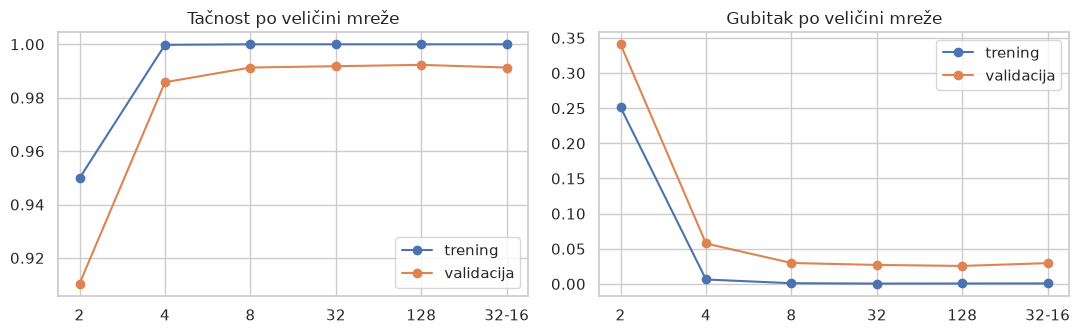

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
x = np.arange(len(sweep))
ax[0].plot(x, sweep["train_acc"], "o-", label="trening"); ax[0].plot(x, sweep["val_acc"], "o-", label="validacija")
ax[0].set_xticks(x); ax[0].set_xticklabels(sweep["sloj"]); ax[0].set_title("Tačnost po veličini mreže"); ax[0].legend()
ax[1].plot(x, sweep["train_loss"], "o-", label="trening"); ax[1].plot(x, sweep["val_loss"], "o-", label="validacija")
ax[1].set_xticks(x); ax[1].set_xticklabels(sweep["sloj"]); ax[1].set_title("Gubitak po veličini mreže"); ax[1].legend()
plt.tight_layout(); plt.show()

| neurona | parametara | trening tačnost | validaciona tačnost | validacioni gubitak |
|---|---|---|---|---|
| 2 | 139k | 0.950 | 0.910 | 0.341 |
| 4 | 278k | 0.9998 | 0.986 | 0.057 |
| 8 | 557k | 1.000 | 0.9913 | 0.0298 |
| 32 | 2.2M | 1.000 | 0.9918 | 0.0270 |
| 128 | 8.9M | 1.000 | 0.9923 | 0.0256 |
| 32-16 (2 sloja) | 2.2M | 1.000 | 0.9913 | 0.0296 |


## 2.4 Regularizacija

Mreža sa mnogo parametara (70000 ulaza x broj neurona) lako pamti trening primere. Probam dve zaštite:

* **L2 kazna (`alpha`)** dodaje u gubitak sumu kvadrata težina, pa model preferira male težine, tj. "jednostavnija" rešenja. Premala alpha ne radi ništa, prevelika sprečava učenje.
* **Rano zaustavljanje** je već uključeno.

Radim sweep po `alpha` za mrežu sa 32 neurona.

In [9]:
rows, ahist = [], {}
for a in [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]:
    m, h = train_mlp(Xtr, ytr, Xva, yva, hidden=(32,), alpha=a)
    b = h["best_epoch"] - 1
    rows.append(dict(alpha=a, epoha=h["best_epoch"], train_acc=h["train_acc"][b], val_acc=h["val_acc"][b],
                     train_loss=h["train_loss"][b], val_loss=h["val_loss"][b]))
    ahist[a] = (m, h)
    print(rows[-1])
alpha_df = pd.DataFrame(rows).round(4); alpha_df

{'alpha': 1e-06, 'epoha': 23, 'train_acc': 1.0, 'val_acc': 0.9920501084076127, 'train_loss': 0.00013390220419848476, 'val_loss': 0.025013107564196453}


{'alpha': 1e-05, 'epoha': 21, 'train_acc': 1.0, 'val_acc': 0.9920501084076127, 'train_loss': 0.0001998324776662109, 'val_loss': 0.025345497177090608}


{'alpha': 0.0001, 'epoha': 17, 'train_acc': 1.0, 'val_acc': 0.9918092026017827, 'train_loss': 0.0005434886706287227, 'val_loss': 0.026959883278597305}


{'alpha': 0.001, 'epoha': 25, 'train_acc': 1.0, 'val_acc': 0.9894001445434835, 'train_loss': 0.0009216244954535116, 'val_loss': 0.031582656269869225}


{'alpha': 0.01, 'epoha': 25, 'train_acc': 0.9999397662932177, 'val_acc': 0.9891592387376535, 'train_loss': 0.005000957817773676, 'val_loss': 0.03753185995191208}


,alpha,epoha,train_acc,val_acc,train_loss,val_loss
0,0.0000,23,1.0000,0.9921,0.0001,0.0250
1,0.0000,21,1.0000,0.9921,0.0002,0.0253
2,0.0001,17,1.0000,0.9918,0.0005,0.0270
3,0.0010,25,1.0000,0.9894,0.0009,0.0316
4,0.0100,25,0.9999,0.9892,0.0050,0.0375


Rezultat: za `alpha` od 1e-6 do 1e-4 su rezultati praktično isti (tačnost 0.9918 do 0.9921, gubitak 0.0250 do 0.0270). Jače kazne (1e-3 i 1e-2) **pogoršavaju** rezultat (tačnost 0.989, gubitak 0.032 do 0.038), jer previše stežu težine pa mreža ne može da iskoristi sve feature-e.


## 2.5 Koliko slojeva? Jedan, dva ili tri

Do sada sam imao samo jedan skriveni sloj. Pitanje je da li dodatni slojevi pomažu. Dodatni sloj omogućava mreži da kombinuje već naučene kombinacije feature-a, ali donosi i mnogo više parametara i više mogućnosti za pamćenje trening skupa.

Zato isprobavam **sve kombinacije**, a ne jednu izabranu:

* **1 sloj:** 8, 16, 32, 64, 128 neurona (5 mreža),
* **2 sloja:** svaki od {32, 64, 128} u svakom položaju, ukupno 9 mreža.
* **3 sloja:** svaki od {32, 64} u svakom položaju, ukupno 8 mreža.

In [4]:
widths1 = [8, 16, 32, 64, 128]
widths2 = [32, 64, 128]
widths3 = [32, 64]
grid = ([(a,) for a in widths1]
        + list(itertools.product(widths2, repeat=2))
        + list(itertools.product(widths3, repeat=3)))
print(len(grid), "arhitektura:", grid)

N_IN, N_OUT = Xtr.shape[1], 10

def n_params(h):
    sizes = (N_IN,) + tuple(h) + (N_OUT,)
    return sum(a * b + b for a, b in zip(sizes, sizes[1:]))

def show_arch(h):
    sizes = (N_IN,) + tuple(h) + (N_OUT,)
    print(f"ulaz {sizes[0]}")
    for i, (a, b) in enumerate(zip(sizes, sizes[1:])):
        kind = "izlaz (softmax)" if i == len(sizes) - 2 else "skriveni (ReLU)"
        print(f"  -> Dense {b:<4d} {kind:16s} težina: {a*b:>9,d} + {b} biasa")
    print(f"ukupno parametara: {n_params(h):,}")

rows = []
for hl in grid:
    t = time.time()
    m, h = train_mlp(Xtr, ytr, Xva, yva, hidden=hl, alpha=1e-5, seed=0, max_epochs=30, patience=3)
    b = h["best_epoch"] - 1
    rows.append(dict(hidden=hl, slojeva=len(hl), parametara=n_params(hl), epoha=h["best_epoch"],
                     train_loss=h["train_loss"][b], val_loss=h["val_loss"][b],
                     train_acc=h["train_acc"][b], val_acc=h["val_acc"][b], sekundi=time.time() - t))
    print(rows[-1], flush=True)
arch_df = pd.DataFrame(rows).round(4)
arch_df

22 arhitektura: [(8,), (16,), (32,), (64,), (128,), (32, 32), (32, 64), (32, 128), (64, 32), (64, 64), (64, 128), (128, 32), (128, 64), (128, 128), (32, 32, 32), (32, 32, 64), (32, 64, 32), (32, 64, 64), (64, 32, 32), (64, 32, 64), (64, 64, 32), (64, 64, 64)]


{'hidden': (8,), 'slojeva': 1, 'parametara': 556626, 'epoha': 26, 'train_loss': 0.0005610190115081766, 'val_loss': 0.028482201710143526, 'train_acc': 0.9999698831466088, 'val_acc': 0.9925319200192725, 'sekundi': 74.15361070632935}


{'hidden': (16,), 'slojeva': 1, 'parametara': 1113242, 'epoha': 26, 'train_loss': 0.00024659334422016255, 'val_loss': 0.023561062328605963, 'train_acc': 0.9999698831466088, 'val_acc': 0.9925319200192725, 'sekundi': 150.8509702682495}


{'hidden': (32,), 'slojeva': 1, 'parametara': 2226474, 'epoha': 21, 'train_loss': 0.0001998324776662109, 'val_loss': 0.025345497177090608, 'train_acc': 1.0, 'val_acc': 0.9920501084076127, 'sekundi': 243.51259851455688}


{'hidden': (64,), 'slojeva': 1, 'parametara': 4452938, 'epoha': 17, 'train_loss': 0.00018794705622549173, 'val_loss': 0.024514717233284116, 'train_acc': 1.0, 'val_acc': 0.9922910142134426, 'sekundi': 603.4681301116943}


...

{'hidden': (64, 32, 32), 'slojeva': 3, 'parametara': 4455754, 'epoha': 4, 'train_loss': 0.0007174135423197213, 'val_loss': 0.030894894229100387, 'train_acc': 0.9999397662932177, 'val_acc': 0.991086485184293, 'sekundi': 256.180459022522}


{'hidden': (64, 32, 64), 'slojeva': 3, 'parametara': 4457130, 'epoha': 4, 'train_loss': 0.0004945770559293222, 'val_loss': 0.03004815240817374, 'train_acc': 0.9999397662932177, 'val_acc': 0.9898819561551433, 'sekundi': 264.97016859054565}


{'hidden': (64, 64, 32), 'slojeva': 3, 'parametara': 4458858, 'epoha': 2, 'train_loss': 0.002229436734746353, 'val_loss': 0.030216591648332923, 'train_acc': 0.9998494157330442, 'val_acc': 0.9915682967959528, 'sekundi': 190.75880885124207}


{'hidden': (64, 64, 64), 'slojeva': 3, 'parametara': 4461258, 'epoha': 2, 'train_loss': 0.0020631373023828094, 'val_loss': 0.027118954944749512, 'train_acc': 0.9997289483194796, 'val_acc': 0.9922910142134426, 'sekundi': 185.57051706314087}


,hidden,slojeva,parametara,epoha,train_loss,val_loss,train_acc,val_acc,sekundi
0,"(8,)",1,556626,26,0.0006,0.0285,1.0000,0.9925,74.1536
1,"(16,)",1,1113242,26,0.0002,0.0236,1.0000,0.9925,150.8510
2,"(32,)",1,2226474,21,0.0002,0.0253,1.0000,0.9921,243.5126
3,"(64,)",1,4452938,17,0.0002,0.0245,1.0000,0.9923,603.4681
4,"(128,)",1,8905866,14,0.0002,0.0237,1.0000,0.9921,953.5668
5,"(32, 32)",2,2227530,10,0.0003,0.0258,1.0000,0.9916,154.9273
6,"(32, 64)",2,2228906,10,0.0002,0.0255,1.0000,0.9918,144.5965
7,"(32, 128)",2,2231658,8,0.0002,0.0263,1.0000,0.9923,111.2401
8,"(64, 32)",2,4454698,11,0.0001,0.0246,1.0000,0.9921,431.4672
9,"(64, 64)",2,4457098,8,0.0002,0.0245,1.0000,0.9918,365.8799


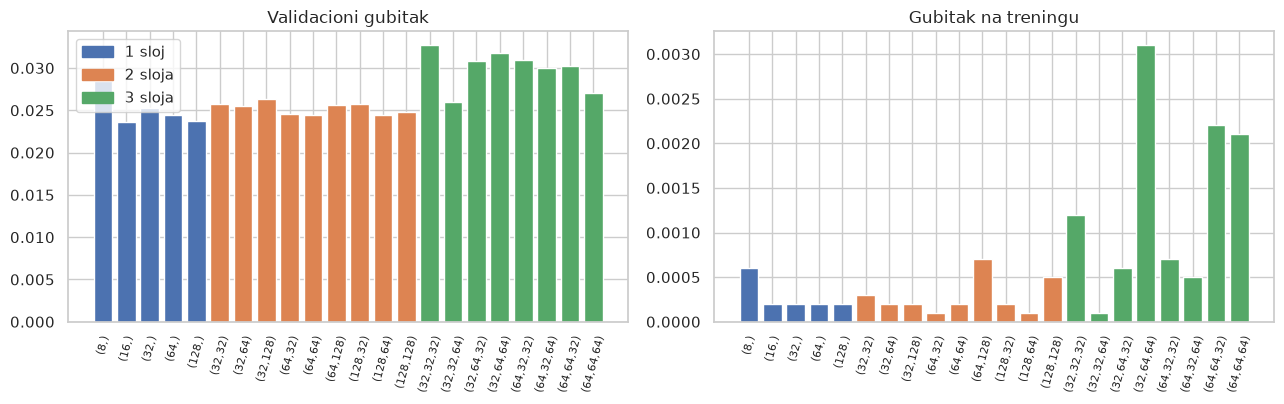

,hidden,slojeva,parametara,train_loss,val_loss,val_acc
1,"(16,)",1,1113242,0.0002,0.0236,0.9925
9,"(64, 64)",2,4457098,0.0002,0.0245,0.9918
15,"(32, 32, 64)",3,2229962,0.0001,0.0260,0.9921


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=False)
colors = {1: "#4c72b0", 2: "#dd8452", 3: "#55a868"}
x = np.arange(len(arch_df))
labels = [str(h).replace(" ", "") for h in arch_df["hidden"]]
for a, col, title in [(ax[0], "val_loss", "Validacioni gubitak"), (ax[1], "train_loss", "Gubitak na treningu")]:
    a.bar(x, arch_df[col], color=[colors[k] for k in arch_df["slojeva"]])
    a.set_xticks(x); a.set_xticklabels(labels, rotation=75, fontsize=8); a.set_title(title)
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=colors[k], label=f"{k} sloj" + ("a" if k > 1 else "")) for k in colors])
plt.tight_layout(); plt.show()

# najbolji rezultat po broju slojeva
arch_df.loc[arch_df.groupby("slojeva")["val_loss"].idxmin(), ["hidden", "slojeva", "parametara", "train_loss", "val_loss", "val_acc"]]

Šta se vidi iz tabele i grafikona:

| najbolja po broju slojeva | parametara | trening gubitak | val gubitak | val tačnost |
|---|---|---|---|---|
| 1 sloj `(16,)` | 1.1M | 0.0002 | **0.0236** | 0.9925 |
| 2 sloja `(64, 64)` | 4.5M | 0.0002 | 0.0245 | 0.9918 |
| 3 sloja `(32, 32, 64)` | 2.2M | 0.0001 | 0.0260 | 0.9921 |

* **Dodatni slojevi ne pomažu.** Nijedna mreža sa 2 ili 3 sloja nije bolja od najbolje jednoslojne.
* **Cena širine:** `(128,)` ima isti gubitak kao `(16,)` (0.0237 prema 0.0236), a ima 8x više parametara i trenira se 6x duže (953 s prema 151 s).


## 2.6 Konačan model i snimanje


In [ ]:
ARCH = (16,)
model, h = train_mlp(Xtr, ytr, Xva, yva, hidden=ARCH, alpha=1e-5, seed=0, max_epochs=30, patience=3)
b = h["best_epoch"] - 1
print(f"najbolja epoha {h['best_epoch']}, val acc {h['val_acc'][b]:.4f}, val loss {h['val_loss'][b]:.4f}")

os.makedirs("../models", exist_ok=True)
joblib.dump({"word_vec": word_vec, "char_vec": char_vec, "model": model, "classes": classes},
            "../models/mlp_model.joblib", compress=3)
print(round(os.path.getsize("../models/mlp_model.joblib") / 1e6, 1), "MB")

saved = joblib.load("../models/mlp_model.joblib")

najbolja epoha 26, val acc 0.9925, val loss 0.0236
oblici matrica težina: [(69566, 16), (16, 10)]


34.8 MB


val acc učitanog modela: 0.9925
